Target CpGs: 49,156
GSE40279: 656 samples | 49156 CpGs | 3,847 completely missing CpGs
GSE55763: 2711 samples | 49156 CpGs | 3,821 completely missing CpGs
GSE111629: 572 samples | 49156 CpGs | 136 completely missing CpGs
GSE157131: 946 samples | 49156 CpGs | 1,580 completely missing CpGs
GSE42861: 689 samples | 49156 CpGs | 136 completely missing CpGs
GSE84727: 665 samples | 49156 CpGs | 4,986 completely missing CpGs
GSE169156: 2052 samples | 49156 CpGs | 1,194 completely missing CpGs
GSE210255: 1394 samples | 49156 CpGs | 1,292 completely missing CpGs
GSE179325: 574 samples | 49156 CpGs | 5,879 completely missing CpGs
PCA on 48,885 probes (coverage >= 50%)


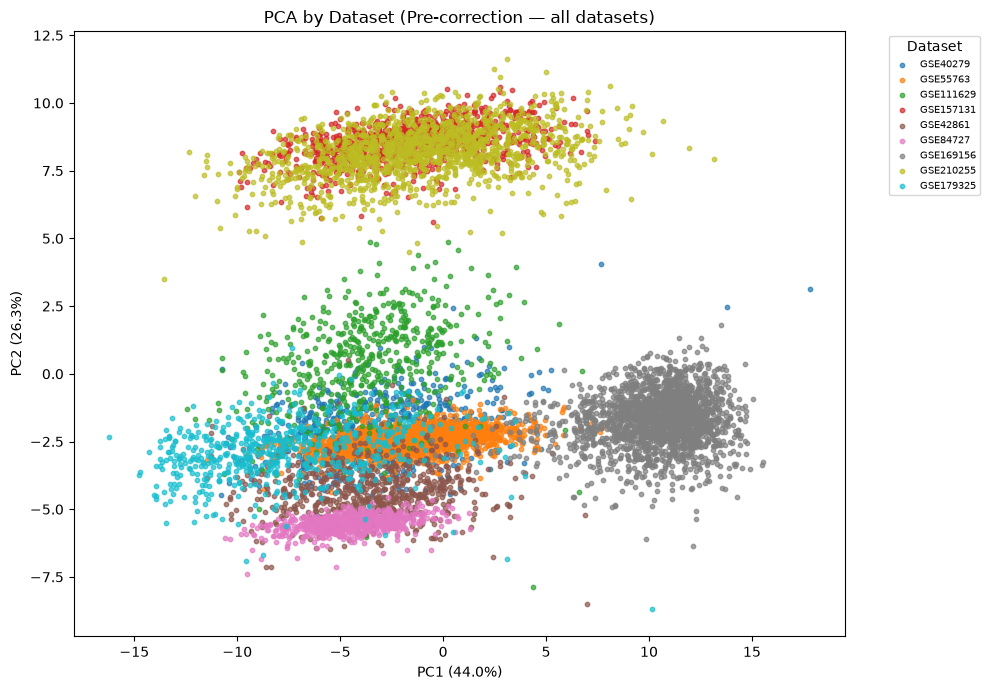

Saved GSE40279 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE40279/methylation.pkl (656 samples, 49156 CpGs)
Saved GSE55763 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE55763/methylation.pkl (2711 samples, 49156 CpGs)
Saved GSE111629 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE111629/methylation.pkl (572 samples, 49156 CpGs)
Saved GSE157131 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE157131/methylation.pkl (946 samples, 49156 CpGs)
Saved GSE42861 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE42861/methylation.pkl (689 samples, 49156 CpGs)
Saved GSE84727 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE84727/methylation.pkl (665 samples, 49156 CpGs)
Saved GSE169156 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE169156/methylation.pkl (2052 samples, 49156 CpGs)
Saved GSE210255 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE210255/methylation.pkl (1394 samples, 49156 CpGs)
Saved GSE179325 -> /work/gr-fe/bryan/EpiHydra/data/03_final/GSE179325/methylation.pkl (574 samples, 49156 CpG

In [3]:

import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.decomposition import PCA
import os

# ── Configuration ─────────────────────────────────────────────────────────────

ALL_DATASETS = [
    # 27K
    # 'GSE41037',
    # 'GSE19711',

    # 450K
    'GSE40279',
    'GSE55763',
    'GSE111629',
    'GSE157131',
    'GSE42861',
    'GSE84727',

    # EPIC
    'GSE169156',
    'GSE210255',
    'GSE179325',
]

DATASETS_TEST = [
    'GSE84727',    # 450K
    'GSE179325',   # EPIC
]

DATASETS_TRAIN = [d for d in ALL_DATASETS if d not in DATASETS_TEST]

SAVE_INDIVIDUAL = True

PROCESSED_DIR = '/work/gr-fe/bryan/EpiHydra/data/02_processed'
FINAL_DIR     = '/work/gr-fe/bryan/EpiHydra/data/03_final'


# ── Load CpG list ─────────────────────────────────────────────────────────────

cpgs = pd.read_csv(
    f'{FINAL_DIR}/methylgpt/probe_ids_type3.csv'
)['illumina_probe_id']

print(f"Target CpGs: {len(cpgs):,}")


# ── Load datasets ─────────────────────────────────────────────────────────────

cpg_list  = []
meta_list = []

for data in ALL_DATASETS:

    filepath = f'{PROCESSED_DIR}/{data}/methylation.pkl'

    with open(filepath, 'rb') as file:
        methylation = pickle.load(file)

    # Reindex to target CpG list.
    # Missing CpGs are retained as NaN.
    cpg_df = methylation['CpG'].reindex(cpgs)

    meta_df = methylation['meta'].copy()
    meta_df['Dataset'] = data

    cpg_list.append(cpg_df)
    meta_list.append(meta_df)

    missing_cpgs = cpg_df.isna().all(axis=1).sum()

    print(
        f"{data}: {cpg_df.shape[1]} samples | "
        f"{cpg_df.shape[0]} CpGs | "
        f"{missing_cpgs:,} completely missing CpGs"
    )

    del methylation


# ── Helper functions ──────────────────────────────────────────────────────────

def plot_pca(X, meta_df, title, min_coverage=0.5):

    # Only use probes present in at least min_coverage fraction of samples
    probe_coverage = X.notna().mean(axis=1)
    X_subset = X.loc[probe_coverage >= min_coverage]

    print(
        f"PCA on {len(X_subset):,} probes "
        f"(coverage >= {min_coverage:.0%})"
    )

    # Median imputation for PCA visualisation only
    X_filled = X_subset.T.fillna(X_subset.median()).T

    # Remove any remaining invalid probes
    X_filled = X_filled.dropna()

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_filled.T)

    datasets = meta_df['Dataset'].unique()
    colours = cm.tab10(np.linspace(0, 1, len(datasets)))
    colour_map = dict(zip(datasets, colours))

    fig, ax = plt.subplots(figsize=(10, 7))

    for dataset in datasets:
        mask = (meta_df['Dataset'] == dataset).values

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            label=dataset,
            color=colour_map[dataset],
            alpha=0.7,
            s=10,
        )

    ax.set_xlabel(
        f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)'
    )
    ax.set_ylabel(
        f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)'
    )

    ax.set_title(title)
    ax.legend(
        title='Dataset',
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        fontsize=7
    )

    plt.tight_layout()
    plt.show()


# ── Pre-combination PCA ───────────────────────────────────────────────────────

combined_pre = pd.concat(cpg_list, axis=1)
combined_meta_pre = pd.concat(meta_list).reset_index(drop=True)

plot_pca(
    combined_pre,
    combined_meta_pre,
    'PCA by Dataset (Pre-correction — all datasets)'
)

del combined_pre, combined_meta_pre


# ── Store individual datasets ─────────────────────────────────────────────────

combined_store = {}

for dataset_name, cpg_df, meta_df in zip(
    ALL_DATASETS, cpg_list, meta_list
):

    combined_store[dataset_name] = {
        'CpG': cpg_df,
        'meta': meta_df
    }


# ── Save individual datasets ──────────────────────────────────────────────────

if SAVE_INDIVIDUAL:

    for dataset_name, data in combined_store.items():

        out_dir = f'{FINAL_DIR}/{dataset_name}'
        out_path = f'{out_dir}/methylation.pkl'

        os.makedirs(out_dir, exist_ok=True)

        with open(out_path, 'wb') as file:
            pickle.dump(data, file)

        print(
            f"Saved {dataset_name} -> {out_path} "
            f"({data['CpG'].shape[1]} samples, "
            f"{data['CpG'].shape[0]} CpGs)"
        )


# ── Build and save train combined ─────────────────────────────────────────────

print(f"\nBuilding TRAIN combined from: {DATASETS_TRAIN}")

train_cpg = pd.concat(
    [combined_store[d]['CpG'] for d in DATASETS_TRAIN],
    axis=1
)

train_meta = pd.concat(
    [combined_store[d]['meta'] for d in DATASETS_TRAIN]
)

print(
    f"Train shape: {train_cpg.shape} | "
    f"Missing: {train_cpg.isna().mean().mean()*100:.1f}%"
)

os.makedirs(f'{FINAL_DIR}/combined_train', exist_ok=True)

with open(
    f'{FINAL_DIR}/combined_train/methylation.pkl', 'wb'
) as file:
    pickle.dump(
        {'CpG': train_cpg, 'meta': train_meta},
        file
    )

print("Train combined saved.")


# ── Build and save test combined ──────────────────────────────────────────────

print(f"\nBuilding TEST combined from: {DATASETS_TEST}")

test_cpg = pd.concat(
    [combined_store[d]['CpG'] for d in DATASETS_TEST],
    axis=1
)

test_meta = pd.concat(
    [combined_store[d]['meta'] for d in DATASETS_TEST]
)

print(
    f"Test shape: {test_cpg.shape} | "
    f"Missing: {test_cpg.isna().mean().mean()*100:.1f}%"
)

os.makedirs(f'{FINAL_DIR}/combined_test', exist_ok=True)

with open(
    f'{FINAL_DIR}/combined_test/methylation.pkl', 'wb'
) as file:
    pickle.dump(
        {'CpG': test_cpg, 'meta': test_meta},
        file
    )

print("Test combined saved.")


In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.decomposition import PCA
from inmoose.pycombat import pycombat_norm
import os

# ── Configuration ─────────────────────────────────────────────────────────────

ALL_DATASETS = [
    # 27K
#    'GSE41037',
#    'GSE19711',
    # 450K
    'GSE40279',
    'GSE55763',
    'GSE111629',
    'GSE157131',
    'GSE42861',
    'GSE84727',
    # EPIC
    'GSE169156',
    'GSE210255',
    'GSE179325',
]

DATASETS_TEST = [
    #'GSE41037',    # 27K
    'GSE84727',    # 450K
    'GSE179325',   # EPIC
]

DATASETS_TRAIN = [d for d in ALL_DATASETS if d not in DATASETS_TEST]

SAVE_INDIVIDUAL = True

PROCESSED_DIR = '/work/gr-fe/bryan/EpiHydra/data/02_processed'
FINAL_DIR     = '/work/gr-fe/bryan/EpiHydra/data/03_final'

# Minimum fraction of samples with a valid measurement for a CpG to be
# included in batch correction. Probes passing this threshold are
# median-imputed before pycombat; NaNs are restored afterwards.
MIN_COVERAGE = 0.80

# Minimum number of valid CpGs required to attempt correction.
# Datasets below this threshold are stored uncorrected.
MIN_VALID_CPGS = 1000

# ── Load data ─────────────────────────────────────────────────────────────────
cpgs = pd.read_csv(f'{FINAL_DIR}/methylgpt/probe_ids_type3.csv')['illumina_probe_id']

cpg_list  = []
meta_list = []
max_i     = 0
best_i    = 0

for i, data in enumerate(ALL_DATASETS):
    filepath = f'{PROCESSED_DIR}/{data}/methylation.pkl'
    with open(filepath, 'rb') as file:
        methylation = pickle.load(file)

    if data == 'GSE210255' : 
        best_i = i

#    if methylation['CpG'].shape[0] > max_i:
#        max_i = methylation['CpG'].shape[0]
#        best_i = i

    cpg_list.append(methylation['CpG'].reindex(cpgs))
    methylation['meta']['Dataset'] = data
    meta_list.append(methylation['meta'])
    del methylation

print(f"Reference dataset (best_i={best_i}): {ALL_DATASETS[best_i]}")
print(f"Train datasets : {DATASETS_TRAIN}")
print(f"Test datasets  : {DATASETS_TEST}")

# ── Helper functions ──────────────────────────────────────────────────────────

def plot_pca(X, meta_df, title, min_coverage=0.5):
    # Only use probes present in at least min_coverage fraction of datasets
    probe_coverage = X.notna().mean(axis=1)
    X_subset = X.loc[probe_coverage >= min_coverage]
    print(f"PCA on {len(X_subset):,} probes (coverage ≥ {min_coverage:.0%})")
    
    X_filled = X_subset.fillna(X_subset.median()).dropna()

    pca      = PCA(n_components=2)
    X_pca    = pca.fit_transform(X_filled.T)

    datasets   = meta_df['Dataset'].unique()
    colours    = cm.tab10(np.linspace(0, 1, len(datasets)))
    colour_map = dict(zip(datasets, colours))

    fig, ax = plt.subplots(figsize=(10, 7))
    for dataset in datasets:
        mask = (meta_df['Dataset'] == dataset).values
        ax.scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            label=dataset, color=colour_map[dataset], alpha=0.7, s=10,
        )
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(title)
    ax.legend(title='Dataset', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7)
    plt.tight_layout()
    plt.show()


def median_impute(df):
    """Impute NaN per CpG (row) with that CpG's median across samples."""
    row_medians = df.median(axis=1)
    return df.T.fillna(row_medians).T

# ── Pre-correction PCA (all datasets) ────────────────────────────────────────
combined_pre      = pd.concat(cpg_list, axis=1)
combined_meta_pre = pd.concat(meta_list).reset_index(drop=True)
plot_pca(combined_pre, combined_meta_pre, 'PCA by Dataset (Pre-correction — all datasets)')
del combined_pre, combined_meta_pre

# ── Pairwise batch correction to reference ────────────────────────────────────
ref_cpg  = cpg_list[best_i].copy()
ref_meta = meta_list[best_i].copy()
ref_meta['Dataset'] = ALL_DATASETS[best_i]

corrected_store = {ALL_DATASETS[best_i]: {'CpG': ref_cpg, 'meta': ref_meta}}

for i, (cpg_df, meta_df) in enumerate(zip(cpg_list, meta_list)):
    if i == best_i:
        continue

    # ── Select CpGs with sufficient coverage in both datasets ─────────────────
    valid_cpgs_ref = ref_cpg.index[ref_cpg.notna().mean(axis=1) >= MIN_COVERAGE]
    valid_cpgs_ds  = cpg_df.index[cpg_df.notna().mean(axis=1)  >= MIN_COVERAGE]
    valid_cpgs     = list(set(valid_cpgs_ref) & set(valid_cpgs_ds))

    print(f"{ALL_DATASETS[i]}: {len(valid_cpgs):,} CpGs valid for correction "
          f"({len(valid_cpgs) / len(ref_cpg.index) * 100:.1f}% of all CpGs, "
          f"coverage threshold={MIN_COVERAGE:.0%})")

    if len(valid_cpgs) < MIN_VALID_CPGS:
        print(f"  Skipping — fewer than {MIN_VALID_CPGS} valid CpGs. "
              f"Storing uncorrected.")
        corrected_store[ALL_DATASETS[i]] = {'CpG': cpg_df.copy(), 'meta': meta_df.copy()}
        continue

    # ── Record original NaN positions to restore after correction ─────────────
    original_nan_mask = cpg_df.loc[valid_cpgs].isna()

    # ── Median-impute within valid subset for pycombat only ───────────────────
    ref_subset = median_impute(ref_cpg.loc[valid_cpgs])
    ds_subset  = median_impute(cpg_df.loc[valid_cpgs])

    # ── Combine and build batch vector ────────────────────────────────────────
    combined = pd.concat([ref_subset, ds_subset], axis=1)
    batch    = [0] * ref_subset.shape[1] + [1] * ds_subset.shape[1]

    covar_age = pd.DataFrame(
        {'age': np.concatenate([ref_meta['age'].values, meta_df['age'].values])},
        index=combined.columns,
    )

    # ── Run pycombat — ref_batch=0 keeps reference samples unchanged ──────────
    # corrected = pycombat_norm(
    #     combined, batch,
    #     ref_batch=0,
    #     covar_mod=covar_age,
    #     na_cov_action='remove',
    # )

    # ── Extract corrected target samples only ─────────────────────────────────
    corrected_ds = combined.iloc[:, ref_subset.shape[1]:]

    # ── Restore original NaN positions ────────────────────────────────────────
    corrected_ds[original_nan_mask] = np.nan

    # ── Place corrected values into full CpG space ────────────────────────────
    corrected_full = pd.DataFrame(np.nan, index=ref_cpg.index, columns=corrected_ds.columns)
    corrected_full.loc[valid_cpgs] = corrected_ds.values

    meta_df = meta_df[meta_df['ID'].isin(corrected_full.columns)]
    corrected_store[ALL_DATASETS[i]] = {'CpG': corrected_full, 'meta': meta_df}

# ── Post-correction PCA (all datasets) ───────────────────────────────────────
all_cpg  = pd.concat([corrected_store[d]['CpG']  for d in ALL_DATASETS], axis=1)
all_meta = pd.concat([corrected_store[d]['meta'] for d in ALL_DATASETS]).reset_index(drop=True)
plot_pca(all_cpg, all_meta, 'PCA by Dataset (Post-correction — all datasets)')
del all_cpg, all_meta

# ── Save individual datasets ──────────────────────────────────────────────────
if SAVE_INDIVIDUAL:
    for dataset_name, data in corrected_store.items():
        out_dir  = f'{FINAL_DIR}/{dataset_name}'
        out_path = f'{out_dir}/methylation.pkl'
        os.makedirs(out_dir, exist_ok=True)
        with open(out_path, 'wb') as file:
            pickle.dump(data, file)
        print(f"Saved {dataset_name} → {out_path} "
              f"({data['CpG'].shape[1]} samples, {data['CpG'].shape[0]} CpGs)")

# ── Build and save train combined ─────────────────────────────────────────────
print(f"\nBuilding TRAIN combined from: {DATASETS_TRAIN}")
missing = [d for d in DATASETS_TRAIN if d not in corrected_store]
if missing:
    raise ValueError(f"Datasets not corrected: {missing}")

train_cpg  = pd.concat([corrected_store[d]['CpG']  for d in DATASETS_TRAIN], axis=1)
train_meta = pd.concat([corrected_store[d]['meta'] for d in DATASETS_TRAIN])

print(f"Train shape : {train_cpg.shape} | "
      f"Missing: {train_cpg.isna().mean().mean()*100:.1f}%")

os.makedirs(f'{FINAL_DIR}/combined_train', exist_ok=True)
with open(f'{FINAL_DIR}/combined_train/methylation.pkl', 'wb') as file:
    pickle.dump({'CpG': train_cpg, 'meta': train_meta}, file)
print("Train combined saved.")

# ── Build and save test combined ──────────────────────────────────────────────
print(f"\nBuilding TEST combined from: {DATASETS_TEST}")
missing = [d for d in DATASETS_TEST if d not in corrected_store]
if missing:
    raise ValueError(f"Datasets not corrected: {missing}")

test_cpg  = pd.concat([corrected_store[d]['CpG']  for d in DATASETS_TEST], axis=1)
test_meta = pd.concat([corrected_store[d]['meta'] for d in DATASETS_TEST])

print(f"Test shape  : {test_cpg.shape} | "
      f"Missing: {test_cpg.isna().mean().mean()*100:.1f}%")

os.makedirs(f'{FINAL_DIR}/combined_test', exist_ok=True)
with open(f'{FINAL_DIR}/combined_test/methylation.pkl', 'wb') as file:
    pickle.dump({'CpG': test_cpg, 'meta': test_meta}, file)
print("Test combined saved.")

ModuleNotFoundError: No module named 'inmoose'